# 03 · Analytics engine: predicting rare-earth imports from the power sector

**Assignment 6.** The engine answers two questions about a country's purchases of Chinese rare-earth
compounds (HS 284690), using **only its power-sector data**:

| Task | Question | Target | Main metric |
|---|---|---|---|
| Regression | How much does the country import in a year? | log10 of imports (kg) | MAE |
| Classification | Is it a **major buyer** (10 tonnes or more a year)? | yes / no | ROC AUC to choose the model; expected business cost to set the threshold |

**Problem type: supervised learning**, a regression and a binary classification on the same rows. Every
row has a known outcome (its recorded imports), so this is not a clustering problem.

**Who acts on it.** The market-development team of a rare-earth supplier, deciding where to spend sales
and sourcing effort. Power data exist for every country and last year's are published before this year's
trade figures, so the engine **forecasts** each country's imports from **last year's** power data, sizes
markets that have no trade records, and turns every prediction into a recommended action (section 8).

**The engine is code, not this notebook.** Everything below calls [`src/modeling/`](../src/modeling/):
`train.py` (data, pipelines, split, tuning, saving), `evaluate.py` (metrics, cross-validation, leakage
checks) and `predict.py` (load and use the saved model). Settings: [`config/model_params.yaml`](../config/model_params.yaml).
From the command line:

```bash
uv run python -m src.modeling.train                # train, evaluate and save the engine
uv run python -m src.modeling.predict              # 2024: expected vs actual, with actions
uv run python -m src.modeling.predict --year 2025  # forecast for a year with no trade data yet
```

Without the real database, this notebook runs on synthetic data and says so; charts are saved to
`docs/figures/` only from real data.

In [1]:
from functools import partial

import pandas as pd
from IPython.display import display

from src.analysis import charts as ch
from src.analysis import exploratory as ex
from src.modeling import evaluate as ev
from src.modeling import predict as pr
from src.modeling import train as tr

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 70)
cfg = tr.load_config()
con, db_path = ex.open_database()
IS_REAL = db_path == ex.REAL_DB
data = tr.load_dataset(con, cfg) if IS_REAL else tr.synthetic_dataset(cfg)
print("Data:", "real database" if IS_REAL else "SYNTHETIC (real database not built): numbers are fake")
FEATURES = tr.feature_columns(cfg)
SOURCE = "Source: China HS 284690 trade (data1.xlsx); Ember yearly electricity data (data2.xlsx)"
show = partial(ch.show, save_figure=IS_REAL)  # charts saved to docs/figures/ only from real data

Data: real database


---
## 1. The data and the two targets

The rows are the Assignment 5 regression sample (Table 1 in notebook 02): country-years with imports,
wind capacity and total generation all recorded. The eight features are all power-sector data, taken
from the **previous year** (`feature_lag_years: 1` in the config): 2023 imports are paired with 2022
power data.

In [2]:
print(f"{len(data)} country-years, {data['country'].nunique()} countries, years {sorted(data['year'].unique())}")
print(f"Major buyers (>= {cfg['target']['major_buyer_kg']:,} kg a year): {data['major_buyer'].mean():.0%} of rows")
print("Features:", FEATURES)
data[FEATURES + ["log10_imports"]].describe().T[["count", "mean", "std", "min", "50%", "max"]]

102 country-years, 58 countries, years [np.int64(2023), np.int64(2024)]
Major buyers (>= 10,000 kg a year): 44% of rows
Features: ['wind_capacity_gw', 'wind_generation_twh', 'solar_capacity_gw', 'total_generation_twh', 'demand_twh', 'renewables_share_pct', 'emissions_intensity_g_per_kwh', 'year']


,count,mean,std,min,50%,max
wind_capacity_gw,102.000,10.352,22.841,0.030,3.095,147.520
wind_generation_twh,102.000,25.774,63.235,0.070,7.395,434.300
solar_capacity_gw,102.000,13.431,24.278,0.020,3.905,139.930
total_generation_twh,102.000,339.054,653.143,4.320,146.815,"4,286.890"
demand_twh,102.000,339.178,655.794,5.330,136.725,"4,328.100"
renewables_share_pct,102.000,39.405,26.345,1.088,34.101,99.915
emissions_intensity_g_per_kwh,102.000,369.415,211.931,25.256,392.853,831.913
year,102.000,"2,023.500",0.502,"2,023.000","2,023.500","2,024.000"
log10_imports,102.000,3.906,1.590,0.301,3.681,7.098


### 1.1 Is every feature available at prediction time?

A feature is only usable if it is known when the prediction is made. Ember publishes a year's power data
after that year ends, at about the time the trade figures appear, so **same-year** power data couldn't
be used to forecast anything. The engine therefore uses **last year's** power data, which are already
published when a forecast is needed. The table checks every feature against the data it will actually
predict from: a 2025 forecast, built from 2024 power data. The documented timing comes from the config,
and a test fails if any feature is undocumented or comes from the trade records.

In [3]:
lag = cfg["data"]["feature_lag_years"]
forecast_rows = tr.load_features(con, [2025], lag) if IS_REAL else data
print(f"Forecasting 2025 from {2025 - lag} power data: {len(forecast_rows)} countries")
ev.feature_availability(forecast_rows, cfg)

Forecasting 2025 from 2024 power data: 68 countries


,feature,known_when,share_present,from_trade_records
0,wind_capacity_gw,"Ember yearly data, published after the year ends; every country",0.971,False
1,wind_generation_twh,"Ember yearly data, published after the year ends; every country",0.985,False
2,solar_capacity_gw,"Ember yearly data, published after the year ends; a few countries ...",0.985,False
3,total_generation_twh,"Ember yearly data, published after the year ends; every country",1.000,False
4,demand_twh,"Ember yearly data, published after the year ends; every country",1.000,False
5,renewables_share_pct,"Ember yearly data, published after the year ends; every country",1.000,False
6,emissions_intensity_g_per_kwh,"Ember yearly data, published after the year ends; every country",1.000,False
7,year,known in advance,1.000,False


Every feature is documented, none comes from trade records, and almost all are present for every
country. The few gaps (a country without solar or wind figures) are filled with the training median
inside the pipeline.

---
## 2. The baseline rule

**Every model is compared with a baseline that ignores the features.** If a model can't beat it, it
isn't useful, however good its other numbers look.
- **`DummyRegressor`** always predicts the training mean of log10 imports. Its R² is about 0 by
  construction.
- **`DummyClassifier`** gives every country the training share of major buyers as its probability, so
  its ROC AUC is exactly 0.5. At its best threshold it flags everyone, which still earns a decent F1
  when 45% of rows are positive: a bar the real model has to clear.

The baseline is the first row of every results table below, and a `beats_baseline` column says whether
each model clears it.

In [4]:
pool = {task: tr.candidates(task, cfg) for task in tr.TASKS}
pd.DataFrame([(task, name, type(pipe.named_steps["model"]).__name__, grid or "none")
              for task, models in pool.items() for name, (pipe, grid) in models.items()],
             columns=["task", "model", "estimator", "hyperparameters searched"])

,task,model,estimator,hyperparameters searched
0,regression,Baseline: mean (DummyRegressor),DummyRegressor,none
1,regression,Linear regression (log-log OLS),LinearRegression,none
2,regression,Ridge regression,Ridge,"{'model__alpha': [0.01, 0.1, 1, 10, 100]}"
3,regression,Random forest,RandomForestRegressor,"{'model__max_depth': [2, 3, 5, None], 'model__min_samples_leaf': [..."
4,classification,Baseline: class share (DummyClassifier),DummyClassifier,none
5,classification,Logistic regression,LogisticRegression,"{'model__C': [0.001, 0.01, 0.1, 1, 10]}"
6,classification,Random forest,RandomForestClassifier,"{'model__max_depth': [2, 3, 5, None], 'model__min_samples_leaf': [..."


---
## 3. Splitting the data

**The test set is a quarter of the countries, held out before anything else.** Both years of a test
country are in the test set, so it measures performance on countries the engine has never seen, which is
exactly how it will be used. The split is stratified, so both sides have a similar share of major
buyers. The test set is used **once**, at the very end: not for choosing models, hyperparameters or
thresholds.

In [5]:
train, test = tr.split_by_country(data, cfg)
X, y, groups = train[FEATURES], train["log10_imports"], train["country"]
print(f"Training: {len(train)} rows from {train['country'].nunique()} countries")
print(f"Test:     {len(test)} rows from {test['country'].nunique()} countries")
print("Countries on both sides:", set(train["country"]) & set(test["country"]) or "none")
print(f"Major-buyer share: training {train['major_buyer'].mean():.0%}, test {test['major_buyer'].mean():.0%}")

Training: 77 rows from 44 countries
Test:     25 rows from 14 countries
Countries on both sides: none
Major-buyer share: training 44%, test 44%


**Is this a time series? Is a time-aware split needed?** The rows cover two years, so the engine is
also checked the way a forecast would be used: train on 2023, test on 2024. The table compares that
time-aware split with the country split, for last year's power data (the engine) and same-year data
(not available in time, shown for comparison).

In [6]:
same_year = tr.load_dataset(con, cfg, lag=0) if IS_REAL else data
linear = pool["regression"]["Linear regression (log-log OLS)"][0]
ev.split_comparison({"Last year's power data (engine)": data, "Same-year power data": same_year},
                    linear, FEATURES, "log10_imports", "regression", [2023], [2024],
                    cfg["split"]["cv_folds"], cfg["split"]["random_state"])

,features,split,MAE,RMSE,R2,error_factor
0,Last year's power data (engine),By country (cross-validated),0.870,1.089,0.421,7.699
1,Last year's power data (engine),"By time: train 2023, test 2024",0.798,1.054,0.512,6.284
2,Same-year power data,By country (cross-validated),0.885,1.114,0.337,8.209
3,Same-year power data,"By time: train 2023, test 2024",0.841,1.114,0.437,6.932


The time-aware score is no worse than the country score, and last year's power data predict as well
as same-year data. So the engine loses nothing by using only data available in time. The main split stays
**by country**, because unseen countries are the harder case: in a time split the same countries sit on
both sides.

---
## 4. Leakage: the failure that costs the most points

**Leakage** means information from the data a model is graded on gets into its training. The scores
then look better than the model will ever do on new data, and every conclusion built on them is wrong.

### 4.1 The classic version

```python
# WRONG: the scaler (or imputer) learns its means from every row, test rows included
X_scaled = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y)
```

Worse still is no split at all: scoring a model on the rows it was trained on. The table compares three
ways of scoring the same model on the training set:
- **No split:** fit and score on the same rows.
- **Classic leak:** preprocessing fitted on all rows, then cross-validated.
- **Pipeline:** everything refitted inside each fold.

In [7]:
ridge = pool["regression"]["Ridge regression"][0].set_params(model__alpha=10)
forest = pool["regression"]["Random forest"][0]
print("Ridge regression (scale-sensitive):")
display(ev.classic_leak_vs_pipeline(ridge, X, y, groups, "regression"))
print("Random forest (flexible):")
ev.classic_leak_vs_pipeline(forest, X, y, groups, "regression")

Ridge regression (scale-sensitive):


,MAE,R2,RMSE,error_factor
No split: score on the training rows,0.721,0.637,0.920,5.265
"Classic leak: preprocess all rows, then split",0.811,0.420,0.984,6.900
Pipeline: preprocess inside each fold,0.808,0.420,0.981,6.868


Random forest (flexible):


,MAE,R2,RMSE,error_factor
No split: score on the training rows,0.247,0.960,0.306,1.767
"Classic leak: preprocess all rows, then split",0.873,0.399,1.059,7.583
Pipeline: preprocess inside each fold,0.873,0.399,1.059,7.583


**Reading the tables** (lower MAE = better):
- **No split is the costly failure.** Scored on its own training rows, the random forest is typically off
  by a factor of under 2. On countries it hasn't seen, it is off by a factor of about 8. A report built on
  the first number would promise over four times the accuracy the engine delivers.
- **The classic preprocessing leak makes no real difference here** (Ridge's MAE moves by less than 0.01),
  because scaling and median-filling learn very little from the held-out rows. It is still a mistake:
  steps that learn more (feature selection, target encoding, oversampling) leak far more, and the pipeline
  rules it out by construction.

### 4.2 Put everything in a pipeline

The fix is structural. Imputation, the log transform, scaling and the model sit in one scikit-learn
`Pipeline`. Every `fit` (in cross-validation, in tuning, in the final training) learns medians and scales
from that fit's training rows only, and `predict` reuses them unchanged on new rows.

In [8]:
pool["regression"]["Linear regression (log-log OLS)"][0]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('size', ...), ('other', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the outp

### 4.3 Other leakage sources to check

**Group leakage: the same country on both sides.** A country's imports barely change between 2023 and
2024 (notebook 02, section 3.3). With random folds, the model meets Japan 2024 in testing after training
on Japan 2023, and simply recognises it.

In [9]:
ev.random_vs_group_cv(forest, X, y, groups)

,MAE,RMSE,R2,error_factor
Random rows (leaky),0.703,0.857,0.664,5.179
By country (GroupKFold),0.873,1.059,0.399,7.583


Random folds make the random forest look far better than it is on new countries. Every split in the
engine is therefore **by country** (`GroupKFold`, `StratifiedGroupKFold`).

**Target leakage: features that come from the target.** The trade value comes from the same customs
records as the quantity being predicted, and import growth is computed from it. The screen flags
columns on the forbidden list in the config, and any column whose rank correlation with the target is
suspiciously high (0.9 or more).

In [10]:
display(ev.leakage_screen(train, FEATURES + cfg["features"]["forbidden"], "log10_imports",
                         cfg["features"]["forbidden"]))
leaky_cfg = {**cfg, "features": {**cfg["features"],
                                 "size": cfg["features"]["size"] + ["imports_from_china_value_kusd"]}}
linear, leaky = (tr.candidates("regression", c)["Linear regression (log-log OLS)"][0] for c in (cfg, leaky_cfg))
folds = ev.group_folds("regression", cfg["split"]["cv_folds"])
pd.DataFrame({"Power-sector features only": ev.cv_scores(linear, X, y, groups, folds, "regression").mean(),
              "Plus the trade value (leak)": ev.cv_scores(leaky, train[tr.feature_columns(leaky_cfg)], y,
                                                          groups, folds, "regression").mean()}
             ).drop(index="fold").T

,column,spearman_rho,flagged,reason
0,imports_from_china_value_kusd,0.905,True,derived from the target or its trade records
1,demand_twh,0.782,False,
2,total_generation_twh,0.769,False,
3,solar_capacity_gw,0.632,False,
4,wind_capacity_gw,0.608,False,
5,wind_generation_twh,0.594,False,
6,emissions_intensity_g_per_kwh,0.139,False,
7,year,0.127,False,
8,renewables_share_pct,-0.105,False,
9,import_growth_pct,0.057,True,derived from the target or its trade records


,MAE,RMSE,R2,error_factor
Power-sector features only,0.789,1.001,0.410,6.641
Plus the trade value (leak),0.491,0.607,0.767,3.240


Adding the trade value would make the engine look far better, and it would be useless: anyone who
knows a country's trade value with China already knows its imports.

**Leakage checklist for this engine**

| Source | Risk here | How the engine prevents it | Checked by |
|---|---|---|---|
| Scoring on training rows | Forest error looks over 4 times smaller | Held-out test countries; cross-validation | 4.1 |
| Preprocessing fitted on all rows (classic) | None measurable here; large for target-based steps | Everything in one `Pipeline` | 4.1, `test_pipeline_learns_medians_and_scales_from_training_rows_only` |
| Same country in training and test | Large: imports barely change year to year | Splits and folds by country | 4.3, `test_split_by_country_keeps_each_country_on_one_side` |
| Features derived from the target | Trade value, import growth | Forbidden list in the config; correlation screen | 4.3, `test_features_never_include_the_target_or_trade_columns` |
| Tuning on the test set | Optimistic test score | Nested cross-validation; the test set is used once | Sections 5–6 |
| Threshold chosen on the test set | Optimistic precision and recall | Threshold chosen on out-of-fold training predictions | 6.3 |
| Information from the future | Same-year power data are published only after the year ends | Features come from the previous year (`feature_lag_years: 1`) | 1.1, 3, `test_lagged_features_use_the_previous_years_power_data` |

---
## 5. Regression: how much does a country import?

### 5.1 Evaluation metrics: MAE, RMSE and R²

The target is log10 of kilograms, so errors are in powers of ten:
- **MAE (mean absolute error):** the typical miss. An MAE of 0.85 means a typical estimate is off by a
  factor of 10^0.85 ≈ 7, shown as `error_factor`.
- **RMSE (root mean squared error):** like MAE, but large misses count more. RMSE well above MAE means
  a few countries are missed badly.
- **R²:** the share of the variation between countries that the model explains. 0 = no better than the
  baseline's mean, 1 = perfect.

**Why MAE on the log scale is the main metric (the business cost of a regression error).** The decision is
which *tier* a market is in: tens of kilograms, tonnes or thousands of tonnes. For that, being twice too
high costs about the same as being twice too low, whatever the country's size. A log-scale error measures
exactly that ratio, and MAE weights every country equally. An error in kilograms would be dominated by the
United States, and would say nothing about the 50 smaller markets the team is choosing between. RMSE is
reported too, to show whether a few countries are missed badly. If over-estimating a market cost more than
under-estimating it (for example, a warehouse built for demand that never comes), an asymmetric loss would
be the right metric instead.

### 5.2 Cross-validation and tuning

Each candidate is scored by **nested cross-validation** on the training set:
- The outer folds (by country) measure performance.
- Inside each outer training fold, a grid search (again by country) picks the hyperparameters.

So no fold is ever scored by a model that was tuned on it. The candidate with the lowest mean MAE wins.
Every metric is reported with its standard deviation across the five folds.

**Hyperparameters:** Ridge and the random forest are grid-searched. Plain linear regression has no
hyperparameters to tune, which is documented rather than skipped: Ridge is its tuned, regularised version,
so if regularisation helped, Ridge would win.

In [11]:
reg = tr.select_model("regression", train, cfg)
reg["summary"]

,model,MAE,MAE_sd,RMSE,RMSE_sd,R2,R2_sd,beats_baseline
0,Baseline: mean (DummyRegressor),1.300,0.220,1.537,0.230,-0.178,0.234,False
1,Linear regression (log-log OLS),0.789,0.193,1.001,0.280,0.410,0.396,True
2,Ridge regression,0.811,0.214,1.009,0.283,0.386,0.443,True
3,Random forest,0.832,0.129,1.032,0.181,0.428,0.281,True


In [12]:
# Hyperparameters chosen in each outer fold (a stable choice is a good sign)
pd.DataFrame({name: folds["params"].astype(str) for name, folds in reg["folds"].items()})

,Baseline: mean (DummyRegressor),Linear regression (log-log OLS),Ridge regression,Random forest
0,{},{},{'model__alpha': 0.01},"{'model__max_depth': 2, 'model__min_samples_leaf': 5}"
1,{},{},{'model__alpha': 0.1},"{'model__max_depth': 5, 'model__min_samples_leaf': 5}"
2,{},{},{'model__alpha': 1},"{'model__max_depth': 5, 'model__min_samples_leaf': 5}"
3,{},{},{'model__alpha': 0.1},"{'model__max_depth': None, 'model__min_samples_leaf': 3}"
4,{},{},{'model__alpha': 0.01},"{'model__max_depth': 2, 'model__min_samples_leaf': 3}"


### 5.3 Final test, once

In [13]:
reg_test = tr.fit_and_test("regression", reg["best"], train, test, cfg)
pd.DataFrame({v["name"]: v["test"] for v in reg_test.values()}).T

,MAE,RMSE,R2,error_factor
Baseline: mean (DummyRegressor),1.553,1.745,-0.017,35.687
Linear regression (log-log OLS),1.022,1.246,0.481,10.527


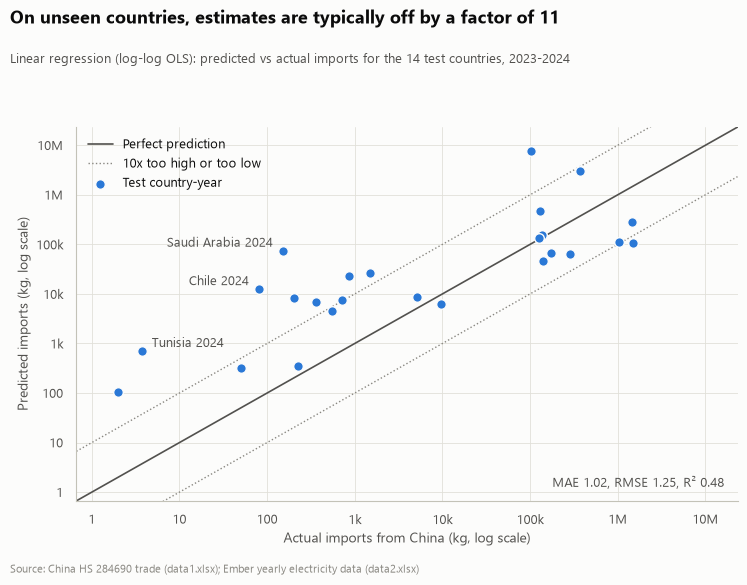

WindowsPath('C:/Users/mcobp/business-analytics-portfolio/docs/figures/13_predicted_vs_actual.png')

In [14]:
pred = reg_test["model"]["fitted"].predict(test[FEATURES])
m = reg_test["model"]["test"]
fig = ch.predicted_vs_actual(
    10 ** test["log10_imports"], 10 ** pred, test["country"] + " " + test["year"].astype(str),
    f"On unseen countries, estimates are typically off by a factor of {m['error_factor']:.0f}",
    f"{reg['best']}: predicted vs actual imports for the {test['country'].nunique()} test countries, 2023-2024",
    SOURCE, note=f"MAE {m['MAE']:.2f}, RMSE {m['RMSE']:.2f}, R\u00b2 {m['R2']:.2f}")
show(fig, "13_predicted_vs_actual")

In [15]:
# How precise is a score from so few test countries? Resample whole countries 1,000 times.
pd.DataFrame([ev.bootstrap_ci(test["log10_imports"], pred, test["country"], "regression", m,
                              random_state=cfg["split"]["random_state"]) for m in ("MAE", "R2")])

,metric,estimate,ci_low,ci_high,n_boot
0,MAE,1.022,0.741,1.312,1000
1,R2,0.481,0.020,0.665,1000


---
## 6. Classification: is a country a major buyer?

### 6.1 Classification metrics: ROC and AUC, precision, recall, F1

The classifier gives each country a **probability** of being a major buyer. A threshold turns it into a
yes/no call.
- **Precision:** of the countries flagged as major buyers, the share that really are. Low precision
  means wasted effort on countries that don't buy much.
- **Recall:** of the real major buyers, the share flagged. Low recall means missed customers.
- **F1:** the harmonic mean of precision and recall. It is high only if both are.
- **ROC curve and AUC:** the ROC curve plots recall (true-positive rate) against the false-positive
  rate for every possible threshold. AUC is the area under it: the chance that a random major buyer
  gets a higher probability than a random smaller buyer. 0.5 is guessing, 1 is perfect. It doesn't
  depend on the threshold, so it is the metric used to **choose the model**.

**The business cost of each error sets the threshold.** For the market-development team the two errors
don't cost the same:
- **A missed major buyer** (false negative) leaves a market of 10 tonnes or more a year unworked: lost
  sales for years.
- **A smaller buyer flagged as major** (false positive) costs one wasted approach: some sales time.

The config sets a miss at **3 times** the cost of a false alarm (`costs` in `model_params.yaml`). That ratio
is a judgement, stated so it can be challenged, and 6.3 shows what changes if it does. The threshold
minimises the **expected cost per country**, which is also reported next to precision, recall and F1. F1
alone would treat the two errors as equally costly.

### 6.2 Cross-validation and tuning

In [16]:
clf = tr.select_model("classification", train, cfg)
clf["summary"]

,model,AUC,AUC_sd,precision,precision_sd,recall,recall_sd,F1,F1_sd,cost,cost_sd,beats_baseline
0,Baseline: class share (DummyClassifier),0.500,0.000,0.442,0.027,1.000,0.000,0.612,0.027,0.558,0.027,False
1,Logistic regression,0.899,0.068,0.618,0.251,0.905,0.147,0.691,0.100,0.478,0.105,True
2,Random forest,0.914,0.073,0.755,0.093,0.881,0.187,0.806,0.116,0.282,0.238,True


In [17]:
pd.DataFrame({name: folds["params"].astype(str) for name, folds in clf["folds"].items()})

,Baseline: class share (DummyClassifier),Logistic regression,Random forest
0,{},{'model__C': 0.001},"{'model__max_depth': 5, 'model__min_samples_leaf': 1}"
1,{},{'model__C': 0.001},"{'model__max_depth': 2, 'model__min_samples_leaf': 1}"
2,{},{'model__C': 0.001},"{'model__max_depth': 5, 'model__min_samples_leaf': 1}"
3,{},{'model__C': 0.001},"{'model__max_depth': 2, 'model__min_samples_leaf': 1}"
4,{},{'model__C': 1},"{'model__max_depth': 2, 'model__min_samples_leaf': 3}"


The shallow random forest has the best mean AUC, just ahead of logistic regression and well within one
standard deviation, and the lowest expected cost. Both beat the baseline on every metric. The forest's
chosen depth is 2 or 5 depending on the fold: with this few countries the data can't pin the settings down,
another sign that more data would help more than a more flexible model.

### 6.3 Choosing the threshold from the business cost, on training data

The threshold is the one with the lowest expected cost on **out-of-fold** predictions for the training
countries (each predicted by a model that never saw it). The first table shows the trade-off: a lower
threshold flags more countries, so recall rises and precision falls. The second shows what each cost ratio
would choose, so the 3:1 judgement can be challenged.

In [18]:
clf_test = tr.fit_and_test("classification", clf["best"], train, test, cfg)
threshold = clf_test["model"]["threshold"]
cv = ev.group_folds("classification", cfg["split"]["cv_folds"], cfg["split"]["random_state"])
oof = ev.out_of_fold_scores(clf_test["model"]["fitted"], X, train["major_buyer"], groups, cv)
print(f"Threshold chosen on training data (lowest expected cost): {threshold}")
ev.threshold_table(train["major_buyer"], oof, thresholds=(0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7),
                   costs=cfg["costs"])

Threshold chosen on training data (lowest expected cost): 0.25


,threshold,precision,recall,F1,accuracy,flagged,cost
0,0.150,0.647,0.971,0.776,0.753,51,0.273
1,0.200,0.717,0.971,0.825,0.818,46,0.208
2,0.250,0.786,0.971,0.868,0.870,42,0.156
3,0.300,0.769,0.882,0.822,0.831,39,0.273
4,0.400,0.743,0.765,0.754,0.779,35,0.429
5,0.500,0.750,0.706,0.727,0.766,32,0.494
6,0.600,0.793,0.676,0.730,0.779,29,0.506
7,0.700,0.846,0.647,0.733,0.792,26,0.519


In [19]:
# If the cost ratio is challenged: the threshold each ratio would choose (training data only)
ratios = [0.2, 0.5, 1, 3, 10]
pd.DataFrame([{"miss costs x false alarm": r,
               "threshold": ev.best_threshold(train["major_buyer"], oof, {"false_negative": r, "false_positive": 1}),
               **ev.classification_metrics(train["major_buyer"], oof,
                                           ev.best_threshold(train["major_buyer"], oof,
                                                             {"false_negative": r, "false_positive": 1}))}
              for r in ratios]).drop(columns=["AUC", "accuracy", "positives", "n"])

,miss costs x false alarm,threshold,precision,recall,F1,flagged
0,0.200,0.800,0.952,0.588,0.727,21
1,0.500,0.800,0.952,0.588,0.727,21
2,1.000,0.250,0.786,0.971,0.868,42
3,3.000,0.250,0.786,0.971,0.868,42
4,10.000,0.250,0.786,0.971,0.868,42


The choice is robust: every ratio from 1:1 to 10:1 picks the same threshold, which misses only one
major buyer in the training countries while keeping false alarms low. Only if a false alarm cost more than
a missed buyer would the threshold rise.

### 6.4 Final test, once

In [20]:
display(pd.DataFrame({v["name"]: v["test"] for v in clf_test.values()}).T)
p_test = clf_test["model"]["fitted"].predict_proba(test[FEATURES])[:, 1]
ev.confusion_table(test["major_buyer"], p_test, threshold)

,AUC,precision,recall,F1,accuracy,flagged,positives,n,cost,threshold
Baseline: class share (DummyClassifier),0.500,0.440,1.000,0.611,0.440,25.000,11.000,25.000,0.560,0.400
Random forest,0.955,0.733,1.000,0.846,0.840,15.000,11.000,25.000,0.160,0.250


,Called: Smaller buyer,Called: Major buyer
Actually: Smaller buyer,10,4
Actually: Major buyer,0,11


In [21]:
pd.DataFrame([ev.bootstrap_ci(test["major_buyer"], p_test, test["country"], "classification", m,
                              random_state=cfg["split"]["random_state"], threshold=threshold,
                              costs=cfg["costs"]) for m in ("AUC", "cost", "recall", "precision")])

,metric,estimate,ci_low,ci_high,n_boot
0,AUC,0.955,0.816,1.000,998
1,cost,0.160,0.000,0.360,1000
2,recall,1.000,1.000,1.000,1000
3,precision,0.733,0.411,1.000,1000


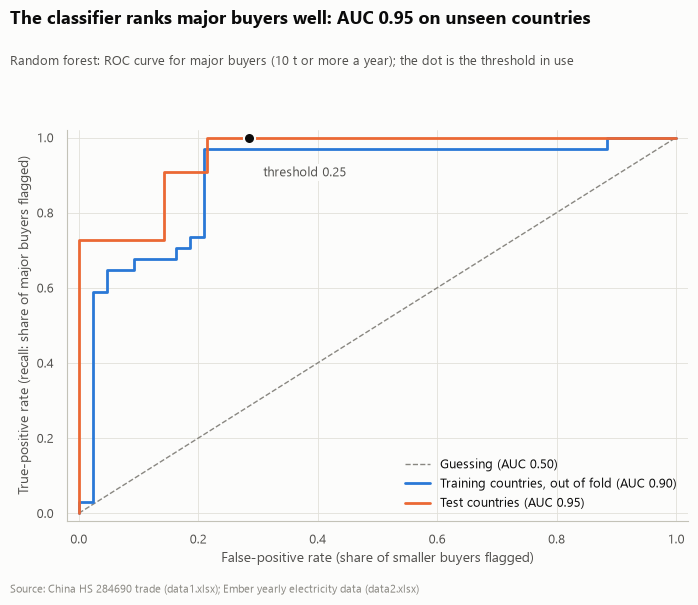

WindowsPath('C:/Users/mcobp/business-analytics-portfolio/docs/figures/14_roc_curve.png')

In [22]:
point = ev.operating_point(test["major_buyer"], p_test, threshold)
curves = {"Training countries, out of fold": ev.roc_points(train["major_buyer"], oof),
          "Test countries": ev.roc_points(test["major_buyer"], p_test)}
fig = ch.roc_chart(
    curves, f"The classifier ranks major buyers well: AUC {curves['Test countries']['AUC']:.2f} on unseen countries",
    f"{clf['best']}: ROC curve for major buyers (10 t or more a year); the dot is the threshold in use",
    SOURCE, marker=(point["fpr"], point["tpr"], f"threshold {threshold:.2f}"))
show(fig, "14_roc_curve")

---
## 7. Every model against the baseline

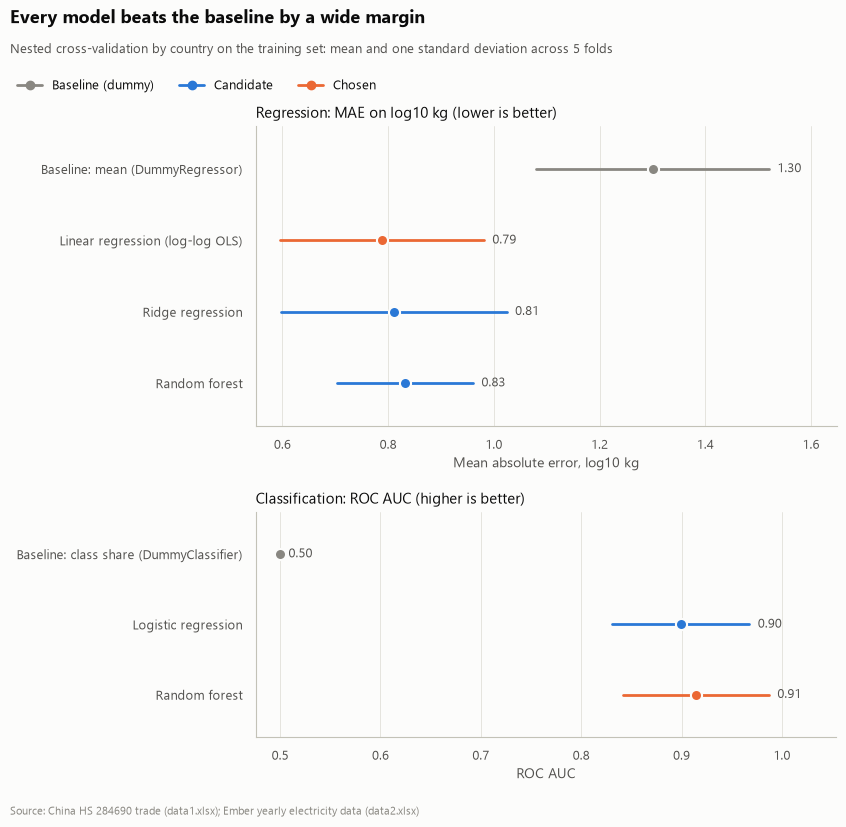

WindowsPath('C:/Users/mcobp/business-analytics-portfolio/docs/figures/12_model_comparison.png')

In [23]:
fig = ch.cv_comparison(
    {"Regression: MAE on log10 kg (lower is better)": (reg["summary"], "MAE", "Mean absolute error, log10 kg"),
     "Classification: ROC AUC (higher is better)": (clf["summary"], "AUC", "ROC AUC")},
    "Every model beats the baseline by a wide margin",
    "Nested cross-validation by country on the training set: mean and one standard deviation across 5 folds",
    SOURCE, chosen={"Regression: MAE on log10 kg (lower is better)": reg["best"],
                    "Classification: ROC AUC (higher is better)": clf["best"]})
show(fig, "12_model_comparison")

---
## 8. Saving the model

The chosen pipelines (preprocessing included) are refitted on **all** the data with their tuned
hyperparameters, then saved with `joblib` as one bundle with what's needed to use and audit them:
- problem types, features and their lag, target definition, models, hyperparameters, threshold and costs;
- cross-validation and test scores, baseline included;
- **provenance:** the data (source, rows, years and a SHA-256 fingerprint of the exact training rows), the
  code (git commit, and whether there were uncommitted changes), a full copy of the config, the
  `random_state`, and the Python and library versions.

`models/` is git-ignored: the saved models are fitted on restricted data. `predict.load_engine` checks the
bundle before use and warns if scikit-learn's version has changed.

One trap was hit and fixed: the log step is a custom function. Run as `python -m src.modeling.train`, it
would be pickled as `__main__.safe_log10`, which no other program can load. `train.py` therefore runs
through its importable module, and a test checks this.

In [24]:
engine = {"data": data, "train": train, "test": test,
          "regression": tr.finish_task("regression", reg, reg_test, data, cfg),
          "classification": tr.finish_task("classification", clf, clf_test, data, cfg)}
bundle = tr.model_bundle(engine, cfg, db_path.name if IS_REAL else "synthetic")
path = tr.save_bundle(bundle, tr.ROOT / (cfg["output"]["model_path"] if IS_REAL
                                         else "models/rare_earth_engine_synthetic.joblib"))
loaded = pr.load_engine(path)
print("Saved and reloaded:", path.relative_to(tr.ROOT))
display({k: loaded[k] for k in ["problem_types", "models", "params", "threshold", "costs", "feature_lag_years"]})
{k: loaded["provenance"][k] for k in ["data", "code", "random_state", "environment", "created_utc"]}

Saved and reloaded: models\rare_earth_engine.joblib


{'problem_types': {'regression': 'Supervised regression: imports from China, log10 kg',
  'classification': 'Supervised binary classification: major buyer or not'},
 'models': {'regression': 'Linear regression (log-log OLS)',
  'classification': 'Random forest'},
 'params': {'regression': {},
  'classification': {'model__max_depth': 2, 'model__min_samples_leaf': 3}},
 'threshold': 0.25,
 'costs': {'false_negative': 3, 'false_positive': 1},
 'feature_lag_years': 1}

{'data': {'source': 'rare_earth.db',
  'rows': 102,
  'countries': 58,
  'years': [2023, 2024],
  'sha256': 'db4c182882dc3aa7fcd01e1fc543c68e1863be5707f46d04ba974fe0cf343f78'},
 'code': {'commit': '5bf97ddff671b1ad12663ee5dd7949fb1bfab9d1',
  'uncommitted_changes': True},
 'random_state': 42,
 'environment': {'python': '3.11.16',
  'platform': 'Windows-10-10.0.26200-SP0',
  'scikit-learn': '1.9.0',
  'pandas': '3.0.5',
  'numpy': '2.4.6',
  'joblib': '1.6.0'},
 'created_utc': '2026-11-19T20:16:45+00:00'}

### From prediction to action

Each 2024 prediction is compared with the country's actual imports and turned into an action for the
market-development team (`predict.recommend`; the cut-offs are in the config):

| Action | Rule | What the team does |
|---|---|---|
| **Approach** | No recorded imports, but a major-buyer call | Investigate it as a new market and approach it |
| **Grow** | A major-buyer call, but buying under 10 t, or under a tenth of what's expected | Prioritise outreach: an under-served market |
| **Verify** | Buying over 10 times what its power sector explains | Plan on its purchase history, not the model, and check end use and re-exports (hubs, manufacturers) |
| **Keep** | A major buyer within a factor of 10 of expectation | Maintain the relationship |
| **Low priority** | A small market, as expected | No action |

The saved model was refitted on all the data, so for countries in the sample these comparisons are
in-sample: read them as *who departs from the pattern*, not as test scores.

In [25]:
features_2024 = tr.load_features(con, [2024], loaded["feature_lag_years"]) if IS_REAL else data[data["year"] == 2024]
actions = pr.recommend(pr.expected_vs_actual(loaded, features_2024), loaded)
cols = ["country", "imports_from_china_kg", "predicted_kg", "ratio_actual_to_expected", "p_major_buyer", "action"]
display(actions["action"].value_counts().rename("countries").to_frame())
for action in ["Approach", "Grow", "Verify", "Keep"]:
    print(f"{action}: {pr.ACTIONS[action]}")
    display(actions[actions["action"] == action][cols].head(6))

,countries
action,
Low priority,30
Keep,23
Verify,8
Grow,6
Approach,1


Approach: No recorded imports, but a major-buyer profile: a possible new market. Investigate and approach.


,country,imports_from_china_kg,predicted_kg,ratio_actual_to_expected,p_major_buyer,action
28,Egypt,NaN,"11,254.120",NaN,0.480,Approach


Grow: A major-buyer profile, but buys under 10 t a year or under a tenth of what its power sector suggests: under-served. Prioritise outreach.


,country,imports_from_china_kg,predicted_kg,ratio_actual_to_expected,p_major_buyer,action
1,India,"103,217.000","4,283,585.959",0.024,0.947,Grow
19,Saudi Arabia,150.000,"37,281.186",0.004,0.522,Grow
21,United Arab Emirates,"2,085.000","19,726.413",0.106,0.357,Grow
23,South Africa,"2,000.000","17,351.572",0.115,0.506,Grow
27,Argentina,"1,475.000","11,267.319",0.131,0.430,Grow
32,Sweden,"1,330.000","6,958.134",0.191,0.500,Grow


Verify: Buys far more than its power sector explains (industry or re-exports): plan on its purchase history, not this model, and check end use.


,country,imports_from_china_kg,predicted_kg,ratio_actual_to_expected,p_major_buyer,action
14,Mexico,"1,022,350.000","57,016.110",17.931,0.841,Verify
33,Netherlands,"4,965,680.000","6,714.398",739.557,0.772,Verify
49,Myanmar,"25,520.000",650.841,39.211,0.137,Verify
50,Ecuador,"16,106.000",644.401,24.994,0.134,Verify
51,Singapore,"61,356.900",581.370,105.538,0.125,Verify
60,Costa Rica,"1,000.000",94.501,10.582,0.120,Verify


Keep: An established major buyer, within a factor of 10 of what its power sector suggests: maintain the relationship.


,country,imports_from_china_kg,predicted_kg,ratio_actual_to_expected,p_major_buyer,action
0,United States,"12,517,000.000","13,172,299.608",0.950,0.947,Keep
2,Brazil,"951,771.000","1,087,539.770",0.875,0.892,Keep
3,Japan,"7,933,100.000","1,037,162.598",7.649,0.898,Keep
4,Russia,"758,084.000","632,374.504",1.199,0.665,Keep
5,Germany,"554,224.000","466,614.242",1.188,0.924,Keep
6,Canada,"130,610.000","311,450.794",0.419,0.738,Keep


**The 2025 forecast.** There are no 2025 trade records yet, so this is a pure forecast from 2024 power
data: the expected size of each market, and the chance that it is a major buyer.

In [26]:
pr.expected_vs_actual(loaded, forecast_rows)[["country", "predicted_kg", "p_major_buyer", "major_buyer_call"]].head(10)

,country,predicted_kg,p_major_buyer,major_buyer_call
0,United States,"27,911,963.051",0.947,True
1,India,"10,731,223.687",0.947,True
2,Brazil,"2,381,951.472",0.895,True
3,Japan,"2,035,817.998",0.902,True
4,Russia,"1,417,931.901",0.665,True
5,Germany,"1,276,151.655",0.924,True
6,Bangladesh,"1,142,945.002",0.136,False
7,Canada,"661,854.771",0.735,True
8,Italy,"634,466.041",0.896,True
9,South Korea,"474,865.997",0.808,True


---
## 9. Structuring the engine

| Part | Where | Responsibility |
|---|---|---|
| Settings | `config/model_params.yaml` | Features, forbidden columns, target and major-buyer threshold, split, tuning grids, output path |
| Data and training | `src/modeling/train.py` | `load_dataset`, `split_by_country`, `build_pipeline`, `candidates`, `select_model` (nested CV), `fit_and_test`, `final_model`, `save_bundle`; command line `python -m src.modeling.train` |
| Evaluation | `src/modeling/evaluate.py` | Regression and classification metrics, `cv_scores`, `nested_cv`, `tune`, `choose_threshold`, ROC points, leakage checks |
| Prediction | `src/modeling/predict.py` | `load_engine` (with checks), `predict`, `expected_vs_actual`; command line `python -m src.modeling.predict` |
| Charts | `src/analysis/charts.py` | `cv_comparison`, `predicted_vs_actual`, `roc_chart`, in the portfolio's one chart style |
| Tests | `tests/test_modeling.py` | Leakage guards, metric definitions, split, save-and-reload, baseline beaten; synthetic data, so no restricted files needed |
| Experiments | this notebook | Calls the package only: no function definitions (enforced by a test) |

Every step is a function with a docstring ([API reference](../docs/api_reference.md)), the notebook and
the command line run the same code, and the test suite runs without the restricted data.

---
## 10. Findings and limitations

- **The engine beats the baseline on unseen countries in both tasks.** Last year's power data explain about
  40–50% of the variation in log imports. In cross-validation a typical estimate is off by a factor of about
  6, against 20 for the baseline. On the 14 test countries it is off by about 10, against 36. Good enough
  to place a market in its order of magnitude, not to forecast a contract.
- **Major buyers are identified well.** On the test countries the classifier caught all 11 major buyers
  (AUC 0.95), with 4 false alarms. Its expected cost is 0.16 per country against 0.56 for flagging
  everyone, and the 95% interval (0 to 0.36) stays below the baseline.
- **Simple models win or tie.** Linear regression beats the random forest for amounts. For major buyers a
  forest only 2 levels deep edges logistic regression, within one standard deviation.
- **The departures from the pattern are the business story.** The Netherlands buys about 740 times what
  its power sector suggests and Singapore about 100 times, most likely as trading hubs that pass material
  on; Mexico about 18 times. India and Saudi Arabia buy a small fraction of what's expected: the engine
  flags them as under-served (**Grow**). Hubs and manufacturers need features the power sector can't
  provide (port throughput, magnet output).

**Limitations**
- **Little data.** Two years, 102 country-years, 58 countries. The test set has only 25 rows, so its scores
  are uncertain: test R² could be anywhere from about 0.02 to 0.67. Cross-validation, with its standard
  deviations, is the steadier guide.
- **One product code.** Rare-earth compounds (HS 284690) only; magnets and metals are outside the data.
- **Judgement calls.** The 10-tonne major-buyer line, the 3:1 cost ratio and the action cut-offs are
  business assumptions, stated in the config so they can be changed. The threshold doesn't depend on the
  cost ratio between 1:1 and 10:1.
- **In-sample actions.** The saved model was refitted on all the data, so the 2024 actions describe who
  departs from the pattern, not out-of-sample predictions.
- **Associations, not causes.** A big power sector goes with big imports. That doesn't mean building power
  capacity creates rare-earth demand.
- **The forecast assumes the 2023–2024 pattern holds in 2025.** Export restrictions or price shocks would
  break it.

---
## 11. Analytics checklist

| Item | Where it is met |
|---|---|
| Problem type stated explicitly | Introduction: supervised regression and binary classification, not clustering; also saved in the bundle (`problem_types`) |
| Baseline trained and reported alongside the model | Section 2; the dummy is the first row of every results table and is scored on the same test set |
| Train/test split done correctly, time-aware if time series | Section 3: whole countries held out; a train-2023/test-2024 check for the time dimension |
| All preprocessing inside a `Pipeline` | Section 4.2; a test checks the medians and scales come from training rows only |
| Every feature checked for availability at prediction time | Section 1.1: last year's power data only, documented per feature in the config, coverage checked on the 2025 forecast rows |
| `random_state` set everywhere | One `random_state` in the config, used by the split, every fold, every model and the bootstrap; a test checks every estimator |
| Metric chosen from the business cost of each error type, reasoning written down | Sections 5.1 (log-scale MAE) and 6.1 (missed buyer = 3 false alarms; threshold minimises expected cost; sensitivity in 6.3) |
| Cross-validation with the standard deviation reported | Sections 5.2 and 6.2 (nested, by country; every metric with its `_sd`), figure 12 |
| Hyperparameters tuned, or a documented reason not to | Grid search inside each fold for Ridge, logistic regression and the forests; plain linear regression has none (5.2) |
| Full pipeline serialized with provenance | Section 8: preprocessing and model in one bundle, with data fingerprint, git commit, config, `random_state` and versions |
| Model output translated into a recommended action | Section 8: Approach, Grow, Verify, Keep or Low priority for every country, with the reason |
| Limitations stated honestly | Section 10, with bootstrap intervals for the test scores (5.3, 6.4) |